# 1. Understanding the Basics

### • What is Probability ?

Probability is the measure of likelihood of an event.

Formula:
P(Event) = Favorable Outcomes / Total Outcomes

Range: 0 ≤ P ≤ 1

### • Key Probability Terminology

Experiment → Inspecting a product

Sample Space → {Defective, Non-defective}

Event → Product is defective

Outcome → Result of inspection

### • Give at least three probability event examples from the dataset.

#### 1. What is the probability that a randomly chosen student has a previous_test_score of 60 or more? Then find the probability that a student scores below 60.

In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv(r"D:\R&W\07_Mathematic\Practical-1\student_dataset.csv")

n = len(df)

high_score = df["previous_test_score"] >= 60

p_high = high_score.sum() / n
p_low = 1 - p_high

print(f"P(score >= 60) = {high_score.sum()}/{n} = {p_high:.3f}")
print(f"P(score < 60) = {p_low:.3f}")

P(score >= 60) = 156/200 = 0.780
P(score < 60) = 0.220


#### 2. What is the probability that a student has attendance of 75% or more and participates in group discussions? Also find the probability that a student has attendance of 75% or more or participates in group discussions.

In [3]:
n = len(df)

high_attendance = df["attendance"] >= 75

group_participation = df["group_discussion"] == 1

p_and = (high_attendance & group_participation).sum() / n

p_or = (high_attendance | group_participation).sum() / n

print(f"P(Attendance >= 75% AND Group Discussion) = {p_and:.3f}")
print(f"P(Attendance >= 75% OR Group Discussion) = {p_or:.3f}")

P(Attendance >= 75% AND Group Discussion) = 0.000
P(Attendance >= 75% OR Group Discussion) = 0.585


#### 3. Given that a student studies 15 or more hours per week, what is the probability that they pass the exam? Compare it with the overall P(Pass) and say whether study hours and passing look independent.

In [4]:
n = len(df)

high_study = df["study_hours"] >= 15

passed = df["final_exam_pass"] == 1

p_pass = passed.sum() / n

p_pass_given_study = (high_study & passed).sum() / high_study.sum()

print(f"Overall P(Pass) = {p_pass:.3f}")
print(f"P(Pass | Study Hours >= 15) = {p_pass_given_study:.3f}")

if np.isclose(p_pass, p_pass_given_study):
    print("Study hours and passing look independent.")
else:
    print("Study hours and passing do not look independent.")

Overall P(Pass) = 0.000
P(Pass | Study Hours >= 15) = 0.000
Study hours and passing look independent.


# 2. Types of Events

### • Identify one empirical probability and one theoretical probability scenario from the dataset and calculate both.

#### Empirical probability is calculated from observed data.
#### Theoretical probability is calculated using a mathematical model. For 3 independent selections where the probability of passing is p, the number of passes follows a binomial distribution.

In [7]:
from math import comb

empirical_probability = (df['final_exam_pass'] == 'Pass').mean()
print('Empirical probability of passing =', empirical_probability)

p = empirical_probability
k = 2
n_trials = 3
theoretical_probability_exactly_2 = comb(n_trials, k) * (p ** k) * ((1-p) ** (n_trials-k))
print('Theoretical/model probability of exactly 2 passes out of 3 =', theoretical_probability_exactly_2)

Empirical probability of passing = 0.545
Theoretical/model probability of exactly 2 passes out of 3 = 0.405439125


# 3. Random Variable & Probability Distribution


### • Define a random variable for the event “Number of students passing the final exam” out of 3 randomly selected students.

#### Ans: A random variable assigns a number to each outcome of a random experiment.

In [8]:
from math import comb

n, p = 3, 109/200
for k in range(n + 1):
    print(k, round(comb(n, k) * p**k * (1-p)**(n-k), 4))

0 0.0942
1 0.3385
2 0.4054
3 0.1619


### • Construct its probability distribution table.

In [10]:
import pandas as pd
from math import comb

df = pd.read_csv(r"D:\R&W\07_Mathematic\Practical-1\student_dataset.csv")
p = (df["final_exam_pass"] == "Pass").mean() 
q = 1 - p
n = 3

table = pd.DataFrame({"X": range(n + 1)})
table["P(X=x)"] = [comb(n, k) * p**k * q**(n - k) for k in table["X"]]
table["Cumulative"] = table["P(X=x)"].cumsum()

print(table.round(4))
print("Total:", round(table["P(X=x)"].sum(), 4))

   X  P(X=x)  Cumulative
0  0  0.0942      0.0942
1  1  0.3385      0.4327
2  2  0.4054      0.8381
3  3  0.1619      1.0000
Total: 1.0


### • Find the mean and variance of this random variable.

In [12]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"D:\R&W\07_Mathematic\Practical-1\student_dataset.csv")
p = (df["final_exam_pass"] == "Pass").mean()
q = 1 - p
n = 3

print("Mean     =", round(n * p, 4))
print("Variance =", round(n * p * q, 4))
print("Std Dev  =", round(np.sqrt(n * p * q), 4))

Mean     = 1.635
Variance = 0.7439
Std Dev  = 0.8625


# 4. Venn Diagram in Probability

### Draw a Venn diagram showing:
#### •Students who study more than 10 hours/week.
#### • Students who attend more than 80% of classes.
#### • Overlap showing students who satisfy both conditions.


A only          81
B only          12
Both (A ∩ B)    66
Neither         41
dtype: int64


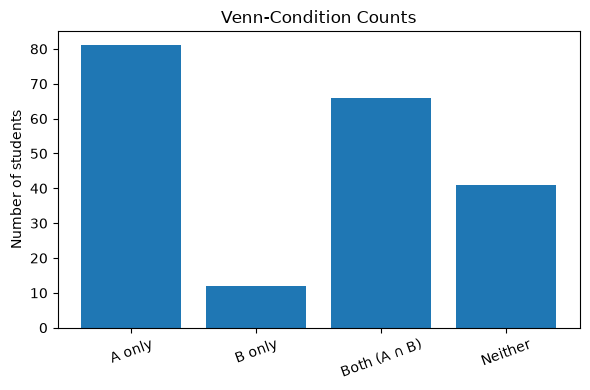

In [14]:
import matplotlib.pyplot as plt

A = df['study_hours'] > 10
B = df['attendance'] > 80
counts = {
    'A only': (A & ~B).sum(),
    'B only': (~A & B).sum(),
    'Both (A ∩ B)': (A & B).sum(),
    'Neither': (~A & ~B).sum()
}
print(pd.Series(counts))

plt.figure(figsize=(6,4))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=20)
plt.ylabel('Number of students')
plt.title('Venn-Condition Counts')
plt.tight_layout()
plt.show()

# 5. Contingency Table & Probability Calculations

In [15]:
table = pd.crosstab(df['group_discussion'], df['final_exam_pass'])
print(table)

total = len(df)
joint_probability = ((df['group_discussion'] == 'Yes') & (df['final_exam_pass'] == 'Pass')).mean()
marginal_probability_pass = (df['final_exam_pass'] == 'Pass').mean()
conditional_probability = (
    ((df['group_discussion'] == 'Yes') & (df['final_exam_pass'] == 'Pass')).sum()
    / (df['group_discussion'] == 'Yes').sum()
)
print('Joint P(Group discussion Yes AND Pass) =', joint_probability)
print('Marginal P(Pass) =', marginal_probability_pass)
print('Conditional P(Pass | Group discussion Yes) =', conditional_probability)

final_exam_pass   Fail  Pass
group_discussion            
No                  31    29
Yes                 60    80
Joint P(Group discussion Yes AND Pass) = 0.4
Marginal P(Pass) = 0.545
Conditional P(Pass | Group discussion Yes) = 0.5714285714285714


# 6. Understanding Relationships


 #### If P(Pass | Group discussion = Yes) is different from P(Pass), the two events are not independent.

#### They are not mutually exclusive because a student can participate in group discussion and pass the exam at the same time.

In [16]:
p_pass_given_yes = conditional_probability
print('P(Pass | Yes) =', p_pass_given_yes)
print('P(Pass) =', marginal_probability_pass)
print('Independent?', np.isclose(p_pass_given_yes, marginal_probability_pass))

P(Pass | Yes) = 0.5714285714285714
P(Pass) = 0.545
Independent? False


# 7. Bayes Theorem Application


In [17]:
p_high_given_pass = 0.70
p_high_given_fail = 0.40
p_high = 0.60
p_pass_dataset = (df['final_exam_pass'] == 'Pass').mean()
bayes_result = (p_high_given_pass * p_pass_dataset) / p_high
print('Estimated P(Pass | High attendance) =', bayes_result)

Estimated P(Pass | High attendance) = 0.6358333333333334
